In [1]:
#Step 1:

#Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
#Step 2:

#Load Dataset: Boston House Price

df = pd.read_csv('boston.csv')
print("Dataset loaded successfully!")


Dataset loaded successfully!


In [4]:
#Understand and inspect the dataset

print("First 5 Records:")
display(df.head())

print("Number of Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe())

First 5 Records:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


Number of Rows and Columns: (506, 14)

Column Names:
Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='object')

Data Types:
CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX          int64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [6]:
#Check missing values and duplicates
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values with median
df = df.fillna(df.median(numeric_only=True))

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nUpdated Dataset Shape:")
print(df.shape)

Missing Values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Duplicate Records:
0

Missing Values After Cleaning:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Updated Dataset Shape:
(506, 14)


In [7]:
#Step 3:

#Select input feature (X) and target (y)
# Select input feature and target
X = df[['RM']]
y = df['MEDV']

print("Input Feature (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature (X):


,RM
0,6.575
1,6.421
2,7.185
3,6.998
4,7.147



Target Variable (y):


,MEDV
0,24.0
1,21.6
2,34.7
3,33.4
4,36.2



Input Shape: (506, 1)
Target Shape: (506,)


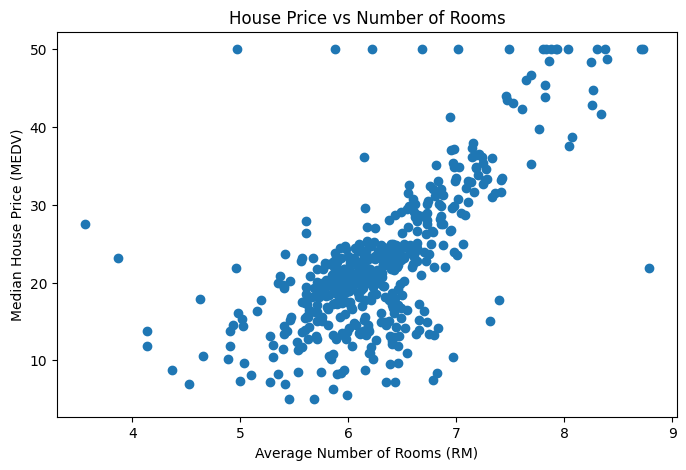

In [8]:
#Step 4:

#Visualise the relationship
plt.figure(figsize=(8,5))

plt.scatter(X['RM'], y)

plt.title("House Price vs Number of Rooms")
plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("Median House Price (MEDV)")

plt.show()

In [9]:
#Step 5:

#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Observations:", len(X_train))
print("Testing Observations:", len(X_test))

Training Data Shape: (404, 1)
Testing Data Shape: (102, 1)
Training Observations: 404
Testing Observations: 102


In [10]:
#Step 6:

#Train Linear Regression model
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Model trained successfully!
Intercept: -36.24631889813795
Coefficient: 9.348301406497727


In [11]:
#Display Regression Eq
print("Regression Equation:")

print(
    f"MEDV = {model.intercept_:.2f} + "
    f"({model.coef_[0]:.2f} * RM)"
)

Regression Equation:
MEDV = -36.25 + (9.35 * RM)


In [12]:
#Step 7:

#Generate predictions
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted Prices:")
display(results.head(10))

Actual vs Predicted Prices:


,Actual Price,Predicted Price
0,23.6,23.732383
1,32.4,26.929502
2,13.6,19.684568
3,22.8,20.451129
4,16.1,22.619935
5,20.0,22.451666
6,17.8,19.039536
7,14.0,21.470094
8,19.6,21.984251
9,16.8,20.095894


In [13]:
#Step 8:

#Evaluate model performance
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 4.478335832064149
MSE: 46.144775347317264
RMSE: 6.792994578778734
R2 Score: 0.3707569232254778


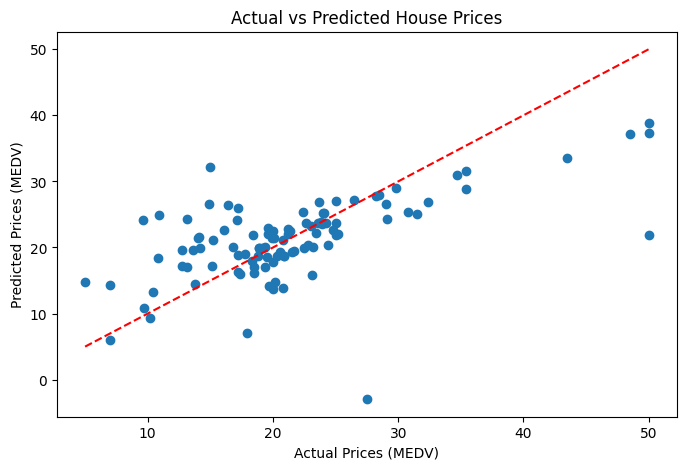

In [14]:
#Step 9:

#Visualise actual vs predicted prices
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices (MEDV)")
plt.ylabel("Predicted Prices (MEDV)")

plt.show()

In [15]:
#Step 10:

#Predict a new house price
new_house = pd.DataFrame({
    'RM': [6.0]
})

predicted_price = model.predict(new_house)

print("Number of Rooms:", 6.0)

print("Predicted House Price (in $1000s):",
      predicted_price[0])

print("Predicted House Price (in dollars):",
      predicted_price[0] * 1000)

Number of Rooms: 6.0
Predicted House Price (in $1000s): 19.843489540848417
Predicted House Price (in dollars): 19843.489540848415


In [18]:
#Conclusion:
print("The Linear Regression model was successfully developed using the Boston Housing dataset. The RM feature was selected as the input variable and MEDV as the target variable. The dataset was divided into training and testing sets in an 80:20 ratio. The model was trained and tested, and its performance was evaluated using MAE, MSE, RMSE and R² score. Actual and predicted prices were visualised and compared. The model can predict house prices, but its accuracy is limited because house prices depend on several factors, not just the number of rooms.")

The Linear Regression model was successfully developed using the Boston Housing dataset. /nThe RM feature was selected as the input variable and MEDV as the target variable. The dataset was divided into training and testing sets in an 80:20 ratio. The model was trained and tested, and its performance was evaluated using MAE, MSE, RMSE and R² score. Actual and predicted prices were visualised and compared. The model can predict house prices, but its accuracy is limited because house prices depend on several factors, not just the number of rooms.
